# **5. ĐÁNH GIÁ MÔ HÌNH**

Đánh giá trên tập kiểm tra (13/06 – 31/07/2015) bằng các chỉ số thường dùng và theo góc nhìn nghiệp vụ: so với baseline, độ tin cậy của P80 và xếp nhân viên.

**5.1 Chuẩn bị dữ liệu**

Đọc dự đoán đã lưu ở notebook 4 (mỗi bài toán một file, mỗi mô hình một cột).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

import features as F

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
PRED_DIR = Path('data/processed/predictions')

def save_fig(name):
    """Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

RUNS = ['customers_h1', 'customers_h7', 'sales_h1', 'sales_h7']
MODELS = ['Tuần trước', 'Cùng KM gần nhất', 'LightGBM']
results = {run: pd.read_parquet(PRED_DIR / f'{run}.parquet') for run in RUNS}
test = {run: res[res['Split'] == 'test'].copy() for run, res in results.items()}
print({run: len(t) for run, t in test.items()})

{'customers_h1': 46998, 'customers_h7': 46998, 'sales_h1': 46998, 'sales_h7': 46998}


**5.2 Bảng chỉ số đánh giá**

In [2]:
def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

def evaluate(actual, pred):
    return {'MAE': mean_absolute_error(actual, pred),
            'RMSE': root_mean_squared_error(actual, pred),
            'RMSPE': rmspe(actual, pred),
            'R²': r2_score(actual, pred)}

rows = []
for run, t in test.items():
    for m in MODELS:
        rows.append({'Bài toán': run, 'Mô hình': m, **evaluate(t['actual'], t[m])})
metrics = pd.DataFrame(rows)
base_mae = metrics[metrics['Mô hình'] == 'Cùng KM gần nhất'].set_index('Bài toán')['MAE']
metrics['Giảm MAE so với "Cùng KM gần nhất" (%)'] = (1 - metrics['MAE'] / metrics['Bài toán'].map(base_mae)) * 100
metrics.round({'MAE': 1, 'RMSE': 1, 'RMSPE': 4, 'R²': 3, 'Giảm MAE so với "Cùng KM gần nhất" (%)': 1})

,Bài toán,Mô hình,MAE,RMSE,RMSPE,R²,"Giảm MAE so với ""Cùng KM gần nhất"" (%)"
0,customers_h1,Tuần trước,126.4,166.4,0.2222,0.816,-98.2
1,customers_h1,Cùng KM gần nhất,63.8,95.0,0.1198,0.940,0.0
2,customers_h1,LightGBM,43.4,63.5,0.0816,0.973,31.9
3,customers_h7,Tuần trước,126.4,166.4,0.2222,0.816,-98.2
4,customers_h7,Cùng KM gần nhất,63.8,95.0,0.1198,0.940,0.0
5,customers_h7,LightGBM,49.1,73.4,0.0919,0.964,23.0
6,sales_h1,Tuần trước,2155.8,2772.2,0.3922,0.195,-167.8
7,sales_h1,Cùng KM gần nhất,805.1,1176.1,0.1559,0.855,0.0
8,sales_h1,LightGBM,532.5,768.7,0.1055,0.938,33.9
9,sales_h7,Tuần trước,2155.8,2772.2,0.3922,0.195,-167.8


MAE theo phần trăm giá trị trung bình, để so được số khách với doanh thu.

In [3]:
lgb_rows = metrics[metrics['Mô hình'] == 'LightGBM'].set_index('Bài toán')
mean_actual = pd.Series({run: t['actual'].mean() for run, t in test.items()})
summary = pd.DataFrame({'Trung bình thực tế': mean_actual.round(0),
                        'MAE LightGBM': lgb_rows['MAE'].round(1),
                        'MAE / trung bình (%)': (lgb_rows['MAE'] / mean_actual * 100).round(1),
                        'RMSPE valid': [rmspe(*results[r].query("Split == 'valid'")[['actual', 'LightGBM']].T.values)
                                        for r in RUNS],
                        'RMSPE test': lgb_rows['RMSPE']}).round(4)
summary

,Trung bình thực tế,MAE LightGBM,MAE / trung bình (%),RMSPE valid,RMSPE test
customers_h1,742.0,43.4,5.9,0.0830,0.0816
customers_h7,742.0,49.1,6.6,0.0919,0.0919
sales_h1,7115.0,532.5,7.5,0.1022,0.1055
sales_h7,7115.0,583.4,8.2,0.1131,0.1142


**Nhận xét:**
- LightGBM giảm MAE so với baseline "Cùng KM gần nhất" 31,9% (số khách, ngày mai), 23,0% (số khách, tuần tới), 33,9% (doanh thu, ngày mai) và 27,5% (doanh thu, tuần tới).
- R² đạt 0,92–0,97.
- MAE chỉ bằng 5,9–6,6% số khách trung bình (742 khách/ngày) và 7,5–8,2% doanh thu trung bình (7.115).
- RMSPE trên tập kiểm định và tập kiểm tra gần như bằng nhau (ví dụ số khách ngày mai: 0,0830 và 0,0816), nên mô hình **ổn định**, kết quả không phải do may mắn trên một tập.
- Số khách dễ dự báo hơn doanh thu, vì doanh thu còn phụ thuộc giá trị mỗi lượt mua.

**5.3 Ngày mai (h = 1) so với tuần tới (h = 7)**

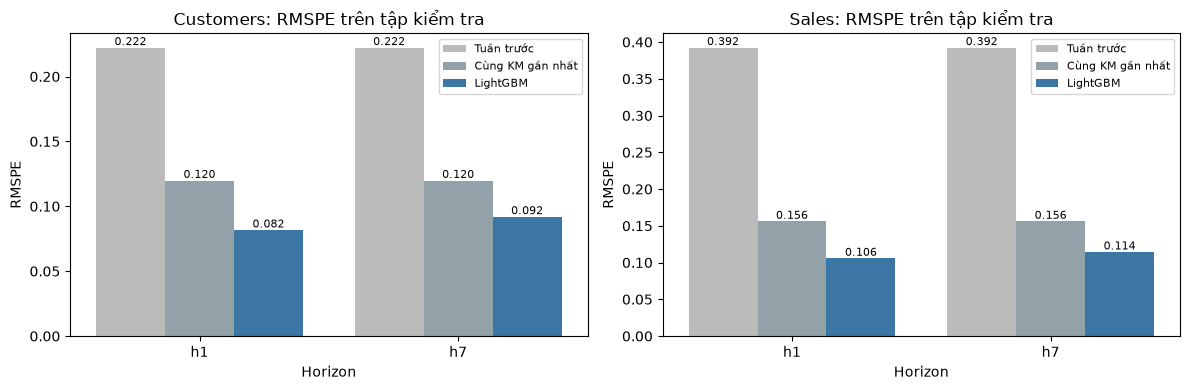

In [4]:
plot_df = metrics.assign(**{'Mục tiêu': metrics['Bài toán'].str.split('_').str[0].str.capitalize(),
                            'Horizon': metrics['Bài toán'].str.split('_').str[1]})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, ['Customers', 'Sales']):
    part = plot_df[plot_df['Mục tiêu'] == target]
    sns.barplot(data=part, x='Horizon', y='RMSPE', hue='Mô hình', ax=ax,
                palette=['#bbbbbb', '#8fa3ad', '#2a78b5'])
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f', fontsize=8)
    ax.set_title(f'{target}: RMSPE trên tập kiểm tra')
    ax.legend(fontsize=8)
save_fig('h1_vs_h7')

**Nhận xét:** dự báo ngày mai chính xác hơn dự báo tuần tới: RMSPE của số khách tăng từ 0,082 (h = 1) lên 0,092 (h = 7), tức khoảng 13%, và của doanh thu từ 0,106 lên 0,114 (khoảng 8%). Đây là giá phải trả khi không có số liệu của 6 ngày gần nhất. Dù vậy, dự báo tuần tới vẫn tốt hơn hẳn baseline tốt nhất (0,120 và 0,156), nên dùng được để xếp lịch trước một tuần. Ngày mai có thể dùng mô hình h = 1 để điều chỉnh lại.

**5.4 Sai số theo thứ trong tuần và theo từng tuần**

      customers_h1  customers_h7  sales_h1  sales_h7
Date                                                
1              6.4           6.5       8.3       8.6
2              5.4           6.6       6.9       8.4
3              5.4           6.4       7.0       7.5
4              6.0           6.9       7.4       8.4
5              5.2           6.3       6.9       7.7
6              6.8           7.2       8.7       8.5
7              6.0           7.1       8.2       8.0
            customers_h1  customers_h7  sales_h1  sales_h7
Date                                                      
2015-06-08           5.6           5.7       7.1       6.4
2015-06-15           4.9           5.4       6.3       6.8
2015-06-22           5.5           5.6       7.2       7.6
2015-06-29           6.3           7.7       8.7       9.4
2015-07-06           6.1           6.7       7.9       8.4
2015-07-13           5.4           5.9       7.0       7.9
2015-07-20           6.0           6.7       7.7   

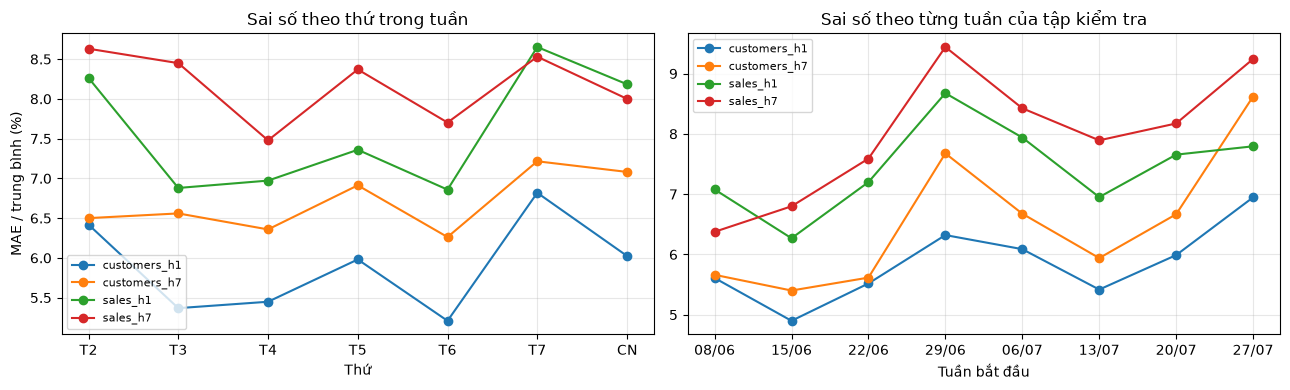

In [5]:
def error_by(t, key):
    g = t.assign(abs_err=(t['actual'] - t['LightGBM']).abs()).groupby(key)
    return g['abs_err'].mean() / g['actual'].mean() * 100          # MAE / trung bình (%)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for run in RUNS:
    t = test[run]
    error_by(t, t['Date'].dt.dayofweek + 1).plot(ax=axes[0], marker='o', label=run)
    by_week = error_by(t, t['Date'].dt.to_period('W').dt.start_time)     # sắp theo thời gian
    by_week.index = by_week.index.strftime('%d/%m')
    by_week.plot(ax=axes[1], marker='o', label=run)
axes[0].set_xticks(range(1, 8), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']); axes[0].set_xlabel('Thứ')
axes[0].set_title('Sai số theo thứ trong tuần'); axes[0].set_ylabel('MAE / trung bình (%)')
axes[1].set_title('Sai số theo từng tuần của tập kiểm tra'); axes[1].set_xlabel('Tuần bắt đầu')
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
save_fig('error_by_dow_week')
print(pd.DataFrame({run: error_by(test[run], test[run]['Date'].dt.dayofweek + 1) for run in RUNS}).round(1))
print(pd.DataFrame({run: error_by(test[run], test[run]['Date'].dt.to_period('W').dt.start_time) for run in RUNS}).round(1))

**Nhận xét:** sai số khá đều giữa các ngày trong tuần. Với số khách ngày mai, sai số từ 5,2% (thứ Sáu) đến 6,8% (thứ Bảy); thứ Hai và thứ Bảy khó đoán hơn một chút. Theo từng tuần của tập kiểm tra, sai số dao động 4,9–6,9% (số khách, ngày mai), cao hơn ở tuần 29/06 và tuần 27/07, nhưng **không tăng dần theo thời gian**. Mô hình học đến 24/04 vẫn dùng tốt sau hơn 3 tháng, chưa cần huấn luyện lại thường xuyên.

**5.5 Mức an toàn P80**

Một mức an toàn tốt cần: (1) tỷ lệ ngày thực tế ≤ P80 gần 80%, (2) không cao hơn mức trung bình quá nhiều (nếu không thì xếp thừa người).

In [6]:
rows = []
for run, t in test.items():
    rows.append({'Bài toán': run,
                 'Thực tế ≤ P80 (%)': (t['actual'] <= t['LightGBM P80']).mean() * 100,
                 'Thực tế ≤ trung bình (%)': (t['actual'] <= t['LightGBM']).mean() * 100,
                 'P80 cao hơn trung bình (%)': (t['LightGBM P80'] / t['LightGBM'] - 1).mean() * 100,
                 'Thực tế vượt P80 quá 10% (%)': (t['actual'] > 1.1 * t['LightGBM P80']).mean() * 100})
pd.DataFrame(rows).set_index('Bài toán').round(1)

,Thực tế ≤ P80 (%),Thực tế ≤ trung bình (%),P80 cao hơn trung bình (%),Thực tế vượt P80 quá 10% (%)
Bài toán,,,,
customers_h1,77.1,52.2,5.0,2.0
customers_h7,78.3,51.6,5.9,2.4
sales_h1,77.2,51.4,6.8,4.1
sales_h7,75.9,50.6,7.2,4.9


**Nhận xét:** trên tập kiểm tra, 75,9–78,3% số ngày thực tế không vượt mức P80, gần mục tiêu 80%. Trong khi đó, mức trung bình chỉ "đủ" khoảng 51–52% số ngày, đúng như kỳ vọng (một nửa đoán thừa, một nửa đoán thiếu). P80 chỉ cao hơn mức trung bình 5–7%, nên không gây thừa người quá nhiều. Số ngày thực tế vượt P80 quá 10% rất hiếm: 2,0–2,4% với số khách, 4,1–4,9% với doanh thu.

**5.6 So sánh thực tế và dự đoán theo thời gian**

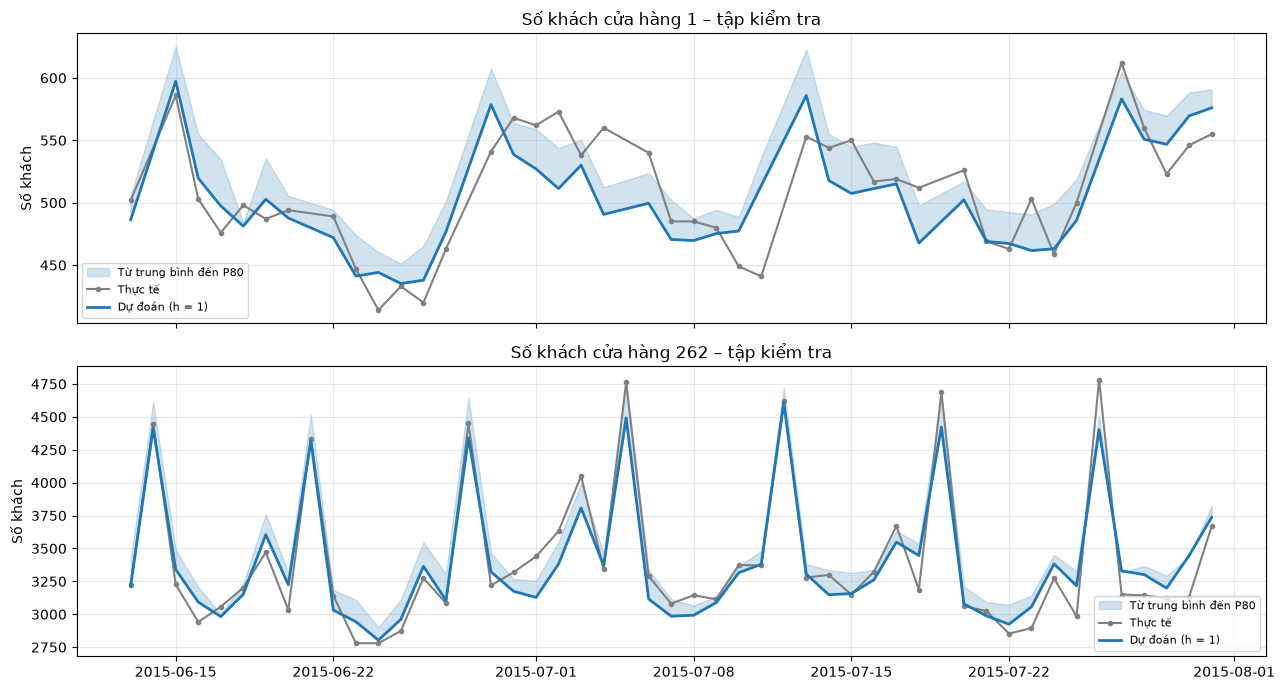

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, store_id in zip(axes, [1, 262]):
    s = test['customers_h1'][test['customers_h1']['Store'] == store_id].sort_values('Date')
    ax.fill_between(s['Date'], s['LightGBM'], s['LightGBM P80'], color='tab:blue', alpha=0.2, label='Từ trung bình đến P80')
    ax.plot(s['Date'], s['actual'], color='gray', marker='.', label='Thực tế')
    ax.plot(s['Date'], s['LightGBM'], color='tab:blue', lw=2, label='Dự đoán (h = 1)')
    ax.set_title(f'Số khách cửa hàng {store_id} – tập kiểm tra'); ax.set_ylabel('Số khách')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
save_fig('customers_store_test')

**Nhận xét:** dự đoán bám sát thực tế ở cả hai cửa hàng. Cửa hàng 262 mở cửa cả Chủ nhật, nên có các đỉnh khoảng 4.500 khách mỗi Chủ nhật, và mô hình bắt được đúng các đỉnh này. Ở cửa hàng 1 (khoảng 450–600 khách/ngày), phần lớn điểm thực tế nằm dưới hoặc gần vùng xanh (từ mức trung bình đến P80). Những ngày lệch nhiều là những biến động bất thường mà các đặc trưng hiện có không giải thích được, ví dụ ngày 10–11/07 ở cửa hàng 1.

**5.7 Ứng dụng: xếp nhân viên cho tuần tới**

Quy số khách (mô hình h = 7) ra số nhân viên bằng `F.staff_needed` (giả định 150 khách/nhân viên, tối thiểu 2 người), rồi so với số nhân viên lẽ ra cần theo số khách thực tế.

In [8]:
PER_STAFF, MIN_STAFF = 150, 2
t = test['customers_h7']
need = F.staff_needed(t['actual'], PER_STAFF, MIN_STAFF)

rows = []
for name, col in [('Cùng KM gần nhất', 'Cùng KM gần nhất'), ('LightGBM (trung bình)', 'LightGBM'),
                  ('LightGBM (P80)', 'LightGBM P80')]:
    plan = F.staff_needed(t[col], PER_STAFF, MIN_STAFF)
    rows.append({'Cách xếp lịch': name,
                 'Ngày thiếu người (%)': (plan < need).mean() * 100,
                 'Ngày thừa người (%)': (plan > need).mean() * 100,
                 'Ngày xếp vừa đủ (%)': (plan == need).mean() * 100,
                 'Ngày-công thiếu': int(np.clip(need - plan, 0, None).sum()),
                 'Ngày-công thừa': int(np.clip(plan - need, 0, None).sum())})
staffing = pd.DataFrame(rows).set_index('Cách xếp lịch').round(1)
staffing

,Ngày thiếu người (%),Ngày thừa người (%),Ngày xếp vừa đủ (%),Ngày-công thiếu,Ngày-công thừa
Cách xếp lịch,,,,,
Cùng KM gần nhất,15.4,22.3,62.3,8156,11766
LightGBM (trung bình),13.6,16.6,69.9,6818,8437
LightGBM (P80),5.0,33.0,62.1,2510,17135


Ví dụ bảng xếp lịch cho cửa hàng 262 trong tuần cuối của dữ liệu.

In [9]:
week = t[(t['Store'] == 262) & t['Date'].between('2015-07-27', '2015-08-02')].copy()
DAY = dict(enumerate(['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']))
pd.DataFrame({'Ngày': week['Date'].dt.dayofweek.map(DAY) + ' ' + week['Date'].dt.strftime('%d/%m'),
              'Khách dự kiến': week['LightGBM'].round(0).astype(int),
              'Mức an toàn P80': week['LightGBM P80'].round(0).astype(int),
              'Nhân viên gợi ý': F.staff_needed(week['LightGBM P80'], PER_STAFF, MIN_STAFF),
              'Khách thực tế': week['actual'].astype(int),
              'Nhân viên lẽ ra cần': F.staff_needed(week['actual'], PER_STAFF, MIN_STAFF)}).reset_index(drop=True)

,Ngày,Khách dự kiến,Mức an toàn P80,Nhân viên gợi ý,Khách thực tế,Nhân viên lẽ ra cần
0,T2 27/07,3268,3355,23,3150,21
1,T3 28/07,3438,3536,24,3143,21
2,T4 29/07,3233,3323,23,3123,21
3,T5 30/07,3512,3577,24,3132,21
4,T6 31/07,3732,3912,27,3669,25


**Nhận xét:** với giả định 150 khách/nhân viên và tối thiểu 2 người, trên 46.998 ngày-cửa hàng của tập kiểm tra:
- **Baseline "Cùng KM gần nhất"**: thiếu người 15,4% số ngày, thừa người 22,3%, xếp vừa đủ 62,3%.
- **LightGBM (trung bình)**: thiếu 13,6%, thừa 16,6%, vừa đủ 69,9% (cao nhất). Tổng ngày-công thiếu giảm từ 8.156 xuống 6.818, ngày-công thừa giảm từ 11.766 xuống 8.437.
- **LightGBM (P80)**: số ngày thiếu người giảm mạnh còn 5,0% và ngày-công thiếu còn 2.510 (giảm 63% so với mức trung bình), đổi lại thừa người 33,0% số ngày (17.135 ngày-công).

Chọn mức nào là **quyết định của quản lý**: nếu thiếu người gây mất khách thì dùng P80; nếu chi phí nhân sự là ưu tiên thì dùng mức trung bình. Web demo cho phép bật/tắt lựa chọn này.

Ví dụ cửa hàng 262, tuần 27/07: P80 gợi ý 23–27 người/ngày trong khi lẽ ra cần 21–25, vì tuần đó khách thực tế (khoảng 3.150) thấp hơn dự kiến (3.230–3.730).

## 5.8 Kết luận

- **LightGBM tốt hơn rõ rệt cách quản lý hay đoán**, giảm MAE 23–34% so với baseline tốt nhất. Số khách dự báo sai trung bình khoảng 6% (43 khách/ngày với h = 1), doanh thu khoảng 7,5–8%.
- **Ngày mai chính xác hơn tuần tới** (RMSPE 0,082 so với 0,092 với số khách), nhưng cả hai đều đủ tốt để dùng: tuần tới để xếp lịch, ngày mai để điều chỉnh.
- **Phát hiện quan trọng nhất**: khuyến mãi chạy xen kẽ từng tuần. Cách đoán "giống tuần trước" vì thế sai gần gấp đôi, và đặc trưng `same_promo` là đặc trưng quan trọng nhất của mô hình.
- **Mức an toàn P80** đúng khoảng 76–78% số ngày trên dữ liệu mới, chỉ cao hơn mức trung bình 5–7%, và giảm ngày-công thiếu người 63%, đổi lại tăng số ngày thừa người.
- **Mô hình ổn định**: kết quả trên tập kiểm định và tập kiểm tra gần như bằng nhau, sai số không tăng dần theo thời gian.

**Hạn chế:** dữ liệu chỉ có theo ngày (chưa xếp được ca theo giờ); doanh thu là tổng (không chia theo mặt hàng); số khách mỗi nhân viên là giả định; ngoài thực tế cần nối với hệ thống bán hàng để có số liệu mới nhất mỗi ngày.

**Hướng phát triển:** dự đoán số khách × giá trị mỗi lượt mua để doanh thu và số khách luôn khớp nhau; hiệu chỉnh P80 bằng tập kiểm định; huấn luyện lại định kỳ trên dữ liệu mới nhất.